# 3 · Les cartes, 2018, et d'où viennent les erreurs

> **En bref**
> - **Sur un épisode simulé**, la note de C désigne la région des fuites ; la carte des débits
>   (bilan q1 − q2) est un bruit de ±2 m³/h où la fuite ne ressort pas à l'œil.
> - **Sur 2018**, la note de C trouve la fuite (top-5 à 300 m) **0,33** du temps, contre 0,15 pour
>   le hasard et 0,25 pour notre modèle d'avant (08c). Le bilan seul : 0,16, mais 0,39 compté par
>   fuite (hasard 0,20).
> - **D'où viennent les erreurs** : tout repose sur le modèle calibré (sans résidu ni dual, hasard) ;
>   la zone C fuit toute l'année et prend une partie du top-5 ; ce qui marche en simulation marche
>   deux fois moins en 2018 ; les débits prédits sont faux en valeur.
> - **Tour 2** (plus de données, conservation, autre choix du modèle, 08c enrichi) : rien ne bat le
>   modèle du tour 1 selon la règle écrite avant. Cette règle utilisait des cartes lissées sur
>   300 m, qui effacent les pics nets et avantagent la fuite de toute l'année en zone C.

In [1]:
import sys
sys.path.insert(0, "..")
from IPython.display import HTML
from conduites import presentation as P

## 1. Les deux cartes de C, sur un épisode simulé

Un épisode de test à trois fuites, choisi comme **typique** (C y fait la médiane des épisodes à
trois fuites), à la dernière heure. Cercles rouges : les vraies fuites ; bleus : les 5 premières
conduites de chaque carte.

,vraie fuite (m³/h),q1 − q2 prédit (m³/h)
p175,3.21,0.18
p773,17.56,-0.17
p851,8.13,0.31


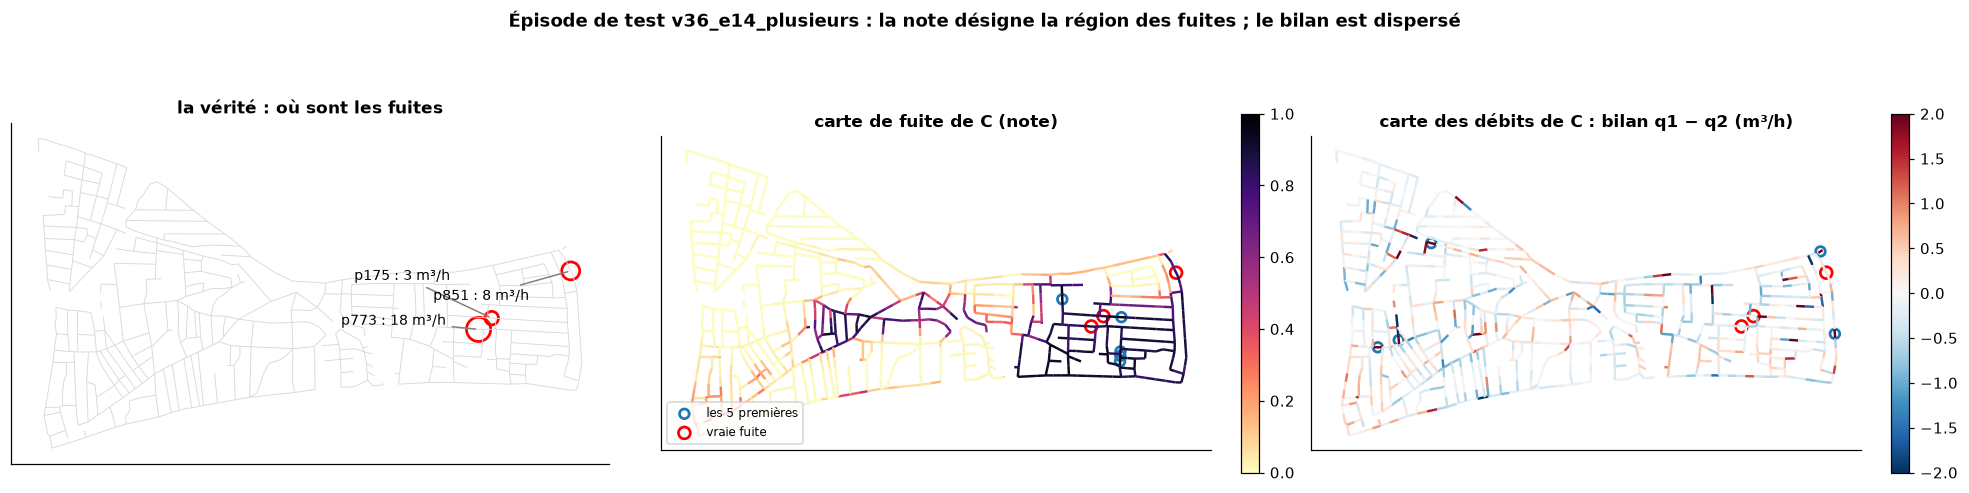

In [2]:
P.cartes_episode()

Ce que la fuite change aux débits du réseau, en vrai et selon C :

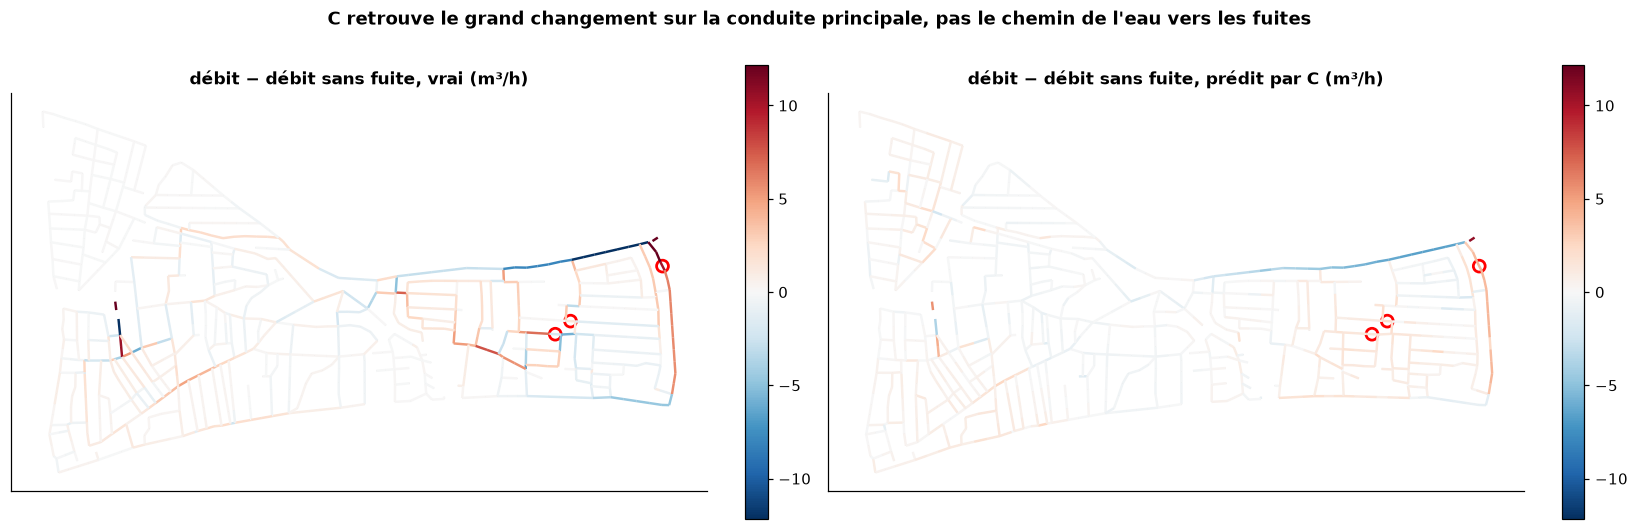

In [3]:
P.carte_dq()

La vraie carte est rouge et bleue le long du chemin de l'eau vers les fuites (jusqu'à ±12 m³/h).
C retrouve le changement sur la grande conduite au nord-est, plus faible, mais presque rien autour
des fuites elles-mêmes.

La carte des débits de C (bilan q1 − q2) pas à pas sur l'épisode :

In [4]:
HTML(P.animation_episode().to_jshtml())

## 2. Sur le vrai 2018

Les mesures de BattLeDIM 2018 (jamais vues), une carte par heure, comparées aux 14 fuites du
fichier officiel. Cartes brutes, sans lissage.

,débit publié (m³/h),q1 − q2 prédit par C (m³/h)
p31,15.98,-0.83
p183,6.84,0.23
p257,6.68,-0.06
p427,5.08,1.14
p654,1.09,-0.13
p810,0.07,-0.39


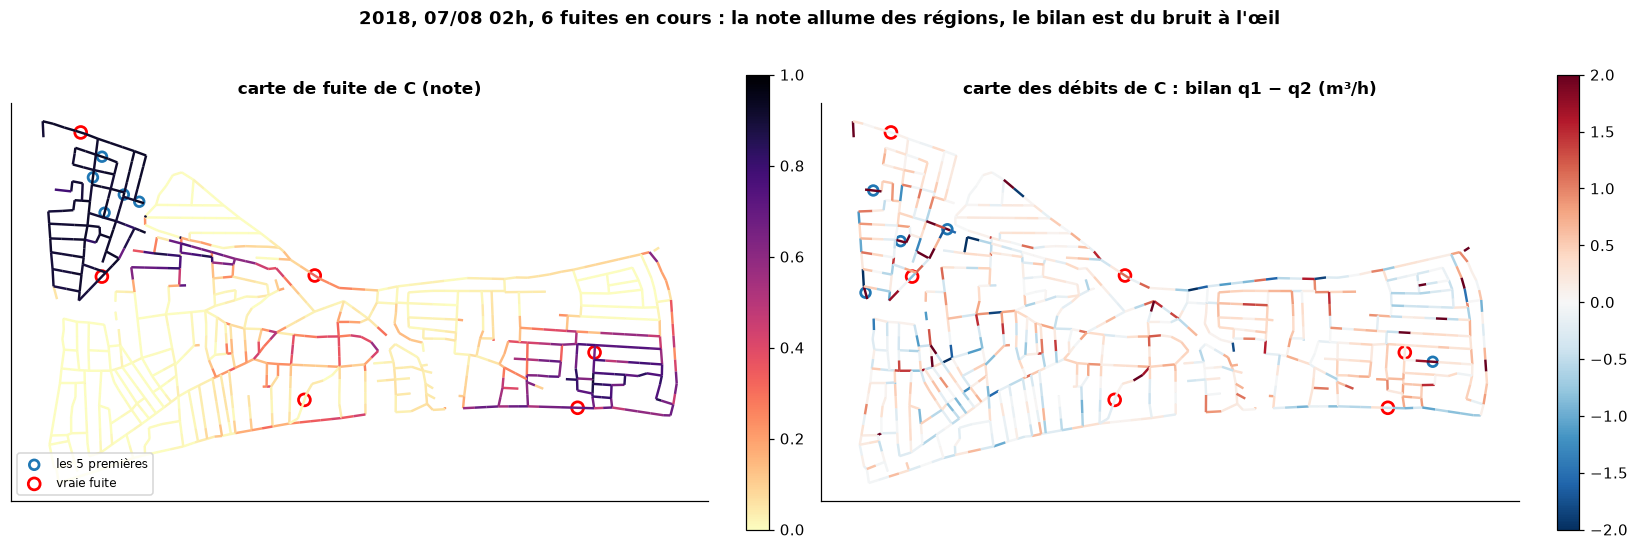

In [5]:
P.cartes_2018_une_heure()

Sur les conduites qui fuient, le bilan prédit vaut entre −0,8 et +1,1 m³/h, pour des fuites
jusqu'à 16 m³/h.

Les notes sur toute l'année. « Par fuite » : chaque fuite pèse pareil, quelle que soit sa durée.
« Hors zone C » : sans les fuites de la zone C (voir section 3).

,toutes les heures,par fuite,hors zone C
C · note,0.33,0.55,0.24
C · bilan,0.16,0.39,0.16
B · note,0.23,0.56,0.26
08c,0.25,0.40,0.13
hasard,0.15,0.20,0.15


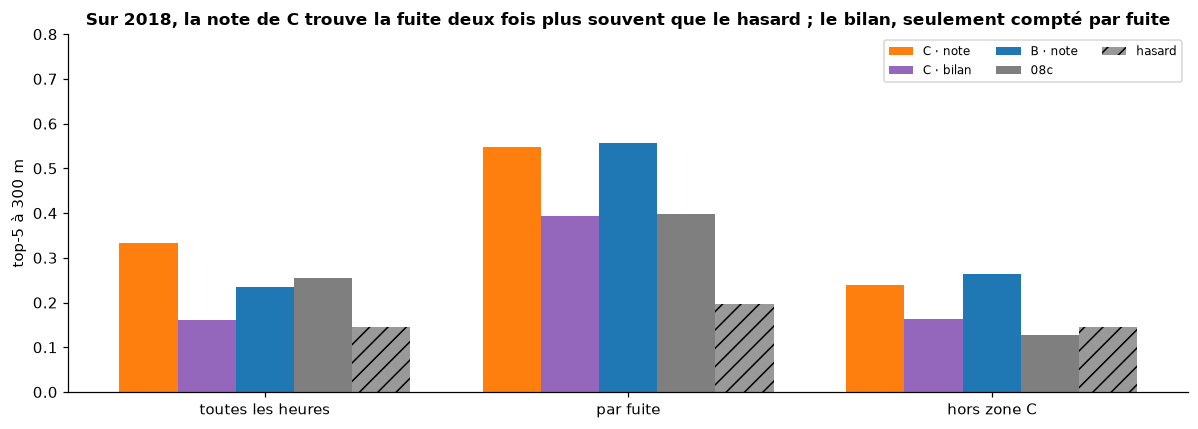

In [6]:
P.scores_2018()

La note de C fait deux fois mieux que le hasard sur toutes les heures, presque trois fois par fuite.
Hors zone C, l'avance se réduit (0,24 contre 0,15). Le bilan n'aide que compté par fuite.

Fuite par fuite : la place médiane de la fuite dans chaque carte, rapportée à celle du hasard
(✓ = mieux que le hasard).

C · note     11
C · bilan    10
B · note     11
08c          11
Name: fuites mieux placées que le hasard (sur 14), dtype: int64

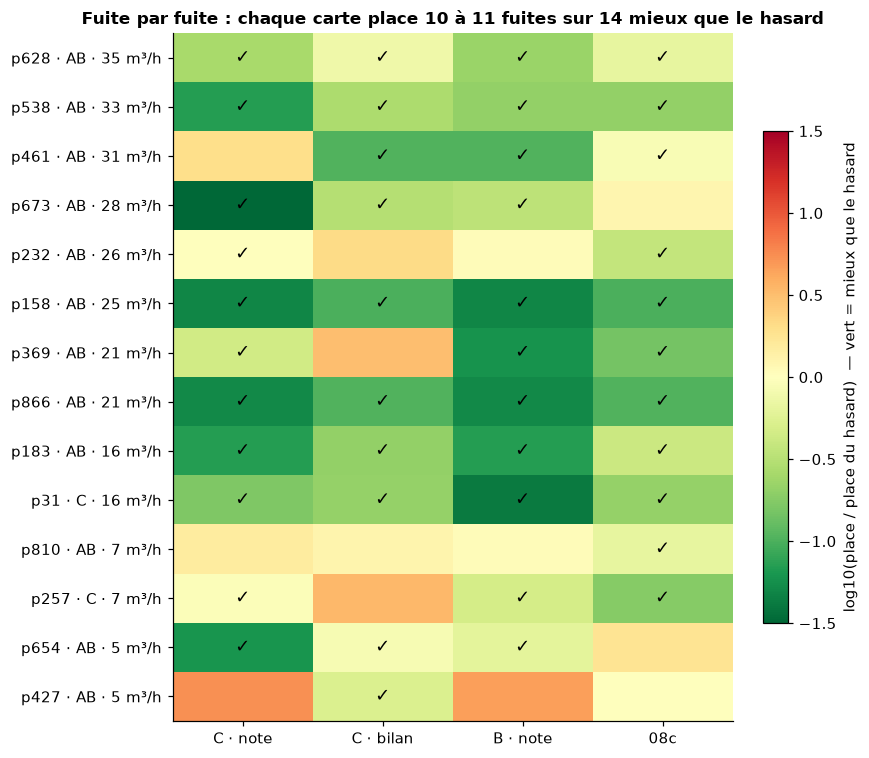

In [7]:
P.par_fuite_2018()

Les grosses fuites sont presque toutes bien placées par toutes les cartes. Les petites fuites lentes
(p810, p427, 5–7 m³/h) restent mal placées, sauf exception. Le bilan est le seul à placer p427.

## 3. D'où viennent les erreurs

### Les entrées : tout repose sur le modèle calibré

Même modèle (ici B), appris sans le résidu ni le dual :

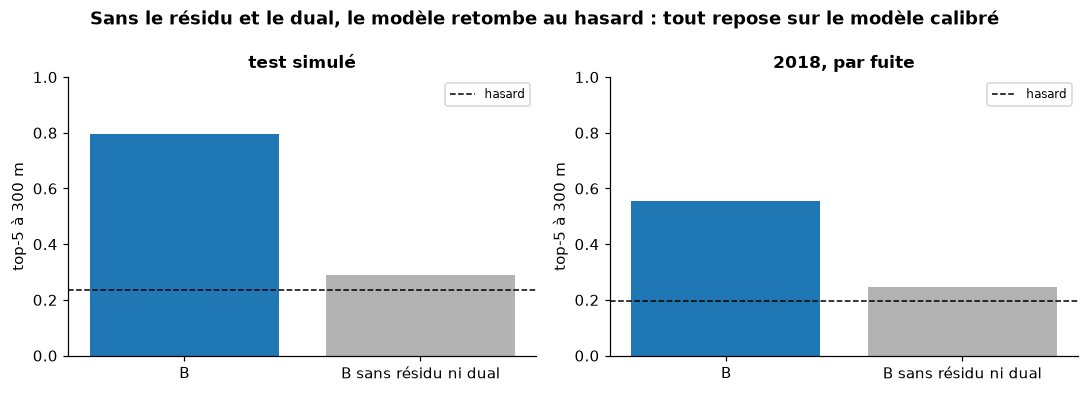

In [8]:
P.retrait_residu_dual()

Le modèle ne sait pas refaire seul la comparaison avec le modèle calibré. Il ne peut donc pas être
meilleur que ce modèle calibré : ses erreurs (8 cm environ) sont du même ordre que l'effet d'une
fuite moyenne.

### La zone C

En 2018, une fuite (p257) coule dans la zone C du 9 janvier au 31 décembre.

heures de 2018 avec une fuite en zone C                         8560
place de p257 parmi les 109 conduites de la zone C (médiane)      39
dtype: int64

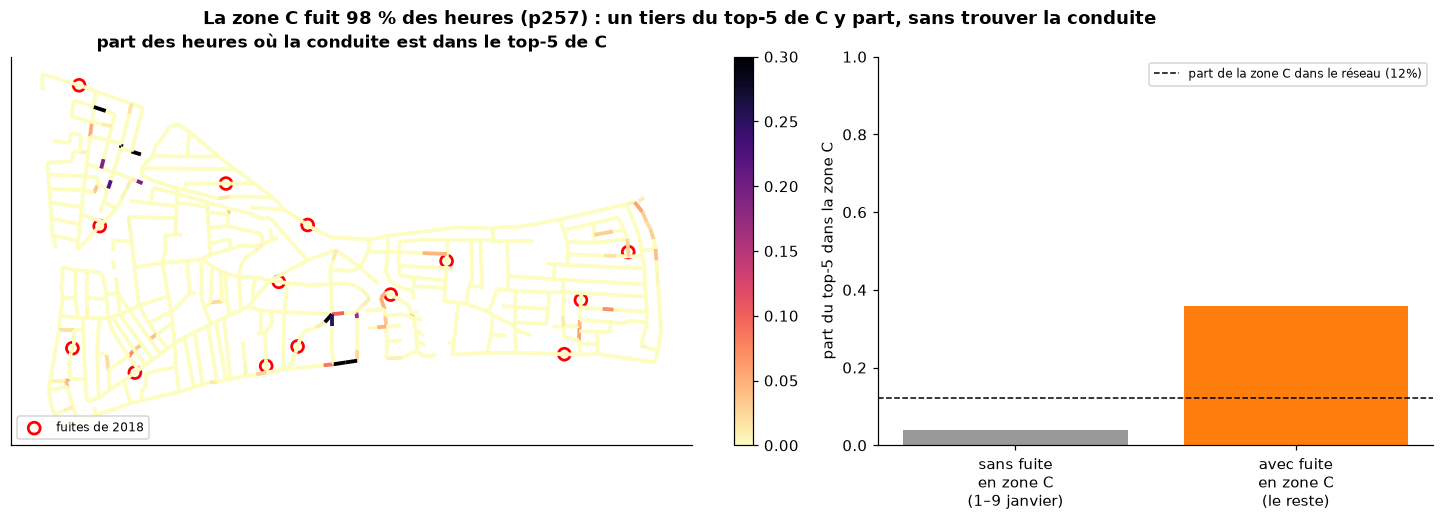

In [9]:
P.zone_c()

Sans fuite en zone C (1–9 janvier), C n'y met presque rien ; avec, un tiers de son top-5 y part,
mais sans trouver p257 (39e sur 109). Cette fuite pèse 98 % des heures : elle tire vers le bas les
notes « toutes les heures ».

### Du simulé au réel

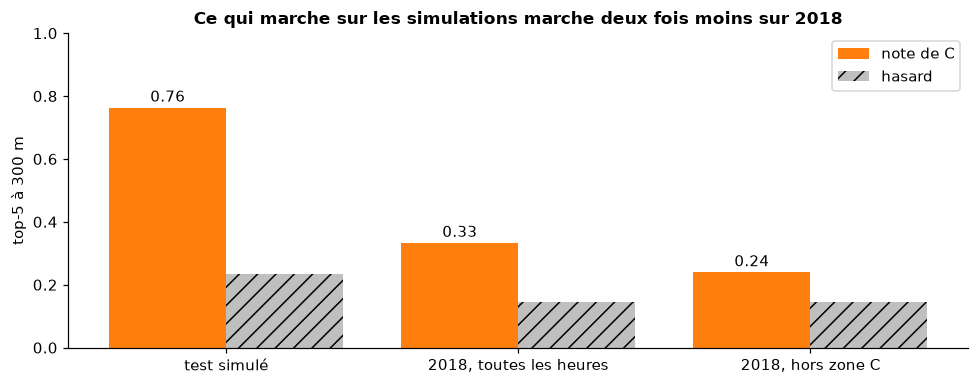

In [10]:
P.simule_contre_reel()

Les simulations ne ressemblent pas assez à 2018 : leurs fuites durent 6 h et sont franches, celles
de 2018 durent des semaines et montent lentement ; l'erreur du modèle calibré y est plus structurée.

### Les débits sont faux en valeur

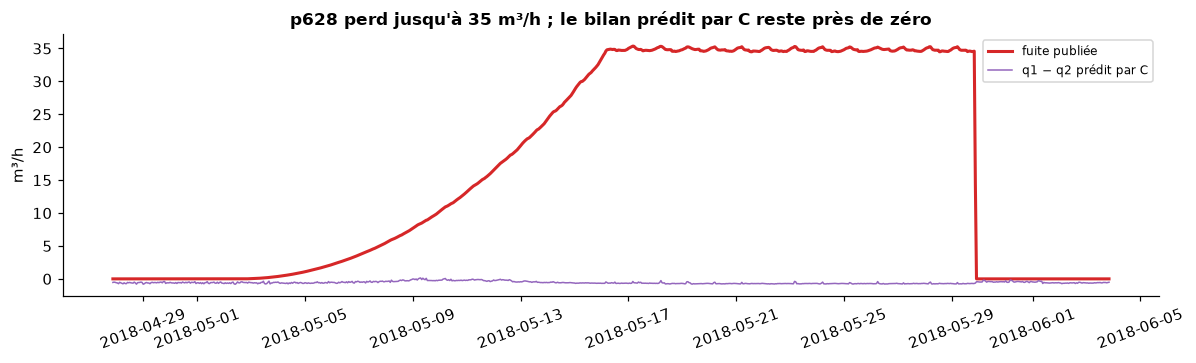

In [11]:
P.bilan_p628()

Le bilan prédit reste près de zéro pendant toute la fuite. En simulation comme en 2018, les débits
de C collent au modèle calibré et la fuite n'y apparaît pas en valeur ; seul l'ordre du bilan porte
un peu d'information.

## 4. Ce qu'on a essayé ensuite (tour 2)

### Cartes brutes ou lissées

Jusqu'ici, toutes les cartes sont **brutes** : la note de chaque conduite telle que le modèle la
donne. Le tour 2 a été jugé sur des cartes **lissées** : la note de chaque conduite est remplacée par
la moyenne de ses voisines à moins de 300 m le long du réseau (plus proche et plus longue = plus de
poids). L'idée : BattLeDIM compte une alarme comme juste à 300 m de la fuite, donc une région devait
valoir mieux qu'une conduite isolée.

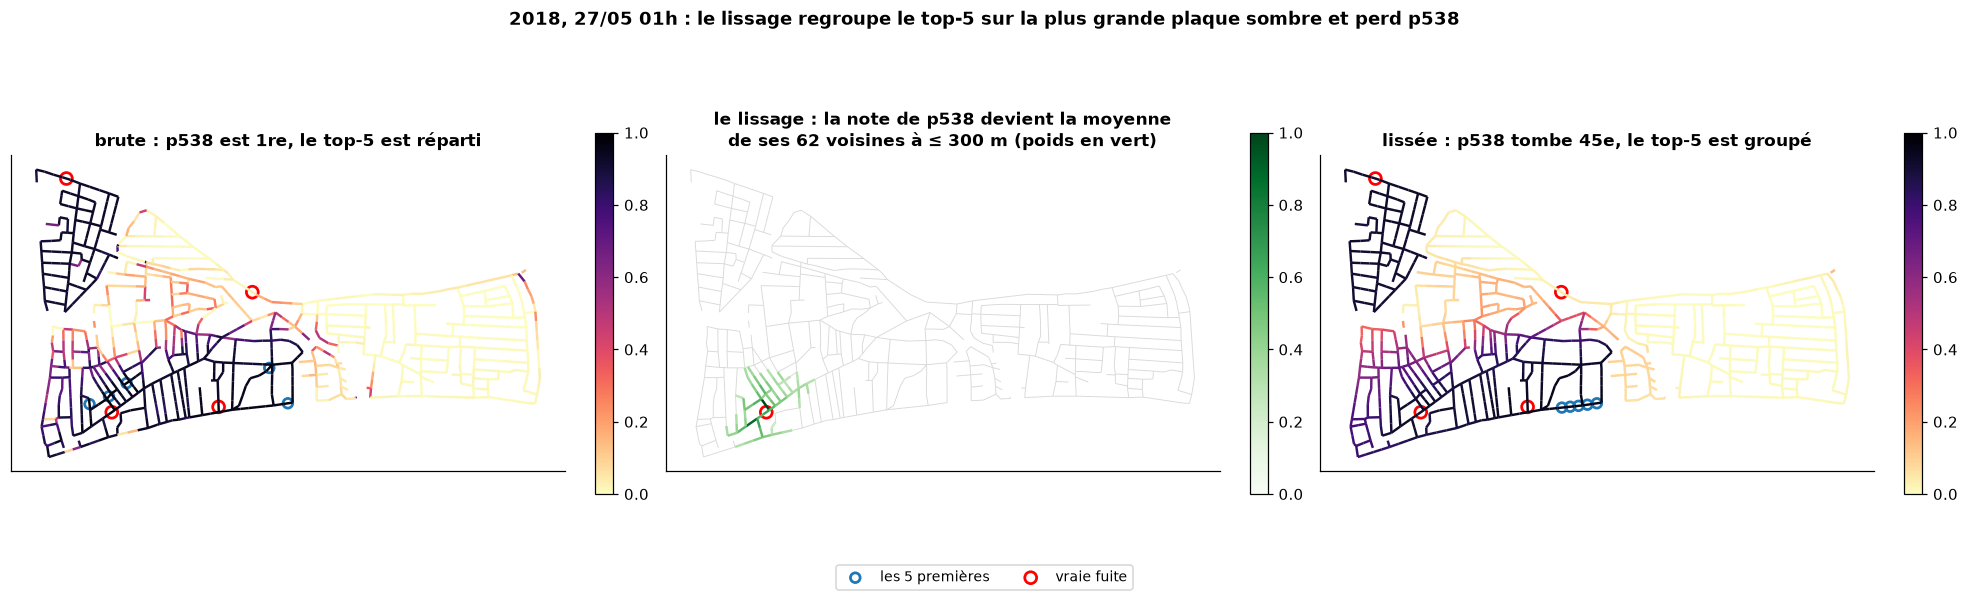

In [12]:
P.brut_contre_lisse()

Le lissage favorise les grandes plaques sombres et efface les pics nets. Sur toute l'année :

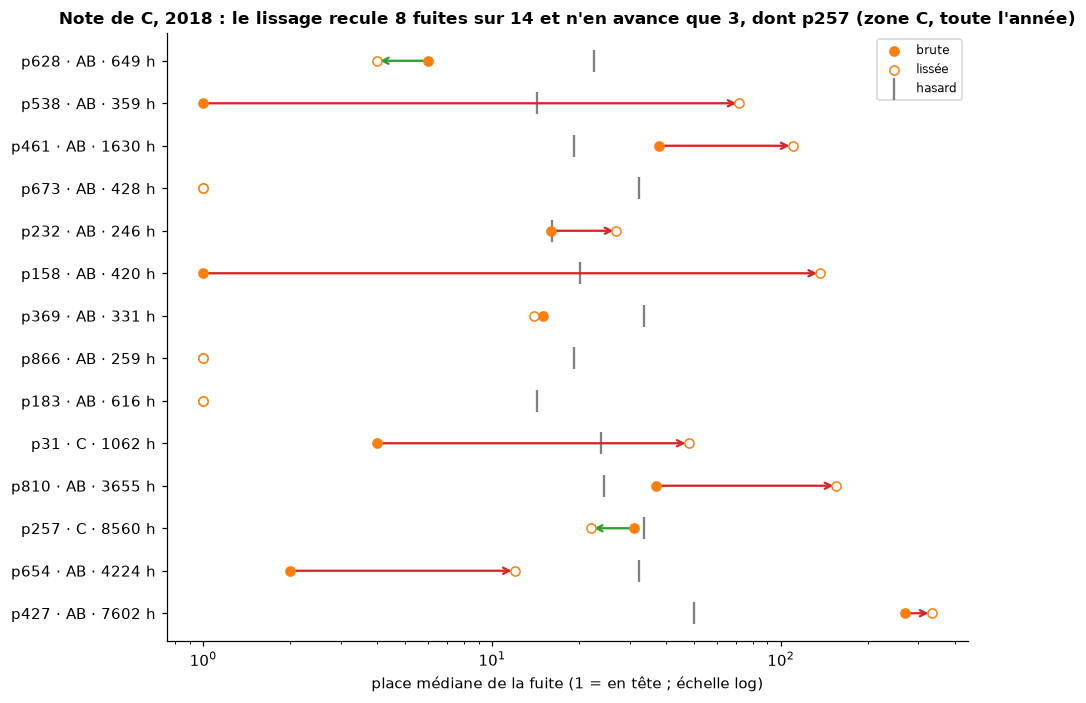

In [13]:
P.brut_contre_lisse_par_fuite();

Le lissage fait reculer 8 fuites sur 14. Il fait avancer p257, la fuite de la zone C qui coule 98 %
des heures : les notes lissées « toutes les heures » sont donc surtout celles de p257.

### Le tableau du tour 2

Règle écrite **avant** les essais : battre le B du tour 1 de plus de 2 points sur l'empreinte 20 %
**et** le top-5, toutes heures **et** hors zone C (cartes lissées sur 300 m, la mesure de l'époque).

In [14]:
P.tour_2()

,empreinte 20 %,top-5,empreinte 20 % hors C,top-5 hors C
B du tour 1 (la référence du critère),0.64,0.32,0.48,0.06
C du tour 1 (le modèle présenté),0.57,0.22,0.35,0.10
C choisi sur le top-5 de validation,0.67,0.35,0.53,0.06
C avec conservation des débits,0.58,0.32,0.39,0.02
"C, données v2 (200 variantes, fuites qui s'arrêtent)",0.60,0.27,0.38,0.10
08c (modèle d'avant),0.38,0.21,0.12,0.02
08c + résidu et dual,0.49,0.25,0.24,0.01


Aucun essai ne remplit la règle. Ce qu'on en tire : choisir le modèle sur le top-5 de validation
n'a pas d'effet net ; la conservation imposée par la perte donne des débits « sans changement »
partout ; plus de variantes simulées n'aide pas sur 2018 ; le résidu et le dual améliorent aussi
le 08c.

## 5. Ce qu'on retient

- **Le modèle suit la cible « où est la fuite »** : bien en simulation (top-5 0,66), deux fois moins
  bien en 2018 (0,33), toujours au-dessus du hasard et du 08c.
- **Il ne suit pas la cible « débits »** : ses débits sont moins justes que le modèle calibré qu'on
  lui donne, et le bilan q1 − q2 ne mesure pas la fuite. La carte des débits ne montre la fuite que
  par son ordre, faiblement.
- **Les limites viennent surtout des données** : le modèle calibré (le modèle ne fait pas mieux que
  lui), l'écart entre simulations et 2018, et la zone C.

**Pistes** (rien n'est lancé) : rapprocher les simulations de 2018 (fuites longues et lentes, erreur
du modèle calibré reproduite) ; imposer la conservation dans l'architecture plutôt que dans la
perte, pour que la carte des débits porte vraiment la fuite ; plusieurs graines.